---
# Milestone 2: Baseline Models

B0 predicts the most frequent training label. B1 uses the original message text with word-level TF-IDF and logistic regression. The shared configuration is stored in `configs/baselines.json`; B1 uses a fixed probability threshold of 0.5.

All fitting uses training data. This section evaluates only validation data and does not load test CSV files. The configured `lbfgs` solver is deterministic, so changing its random seed does not create independent runs.

`no_duplicates` is the main dataset for the preprocessing comparisons. `with_duplicates` is a separate H4 diagnostic with known cross-split leakage. Their validation records differ, so differences between their scores cannot be attributed exclusively to duplication.

Spam F1 is the primary metric. PR-AUC uses trapezoidal integration; average precision (AP) is reported separately. Undefined precision is reported as zero. Confusion matrices use the order `ham`, `spam`.


In [8]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay

from sms_spam.config import load_config
from sms_spam.experiments import RESULTS_DIR, run_experiment

baseline_config = load_config()
display(baseline_config.to_dict())


{'decision_threshold': 0.5,
 'tfidf': {'analyzer': 'word',
  'ngram_range': (1, 1),
  'lowercase': True,
  'strip_accents': None,
  'preprocessor': None,
  'tokenizer': None,
  'token_pattern': '(?u)\\b\\w\\w+\\b',
  'stop_words': None,
  'min_df': 1,
  'max_df': 1.0,
  'max_features': None,
  'binary': False,
  'norm': 'l2',
  'use_idf': True,
  'smooth_idf': True,
  'sublinear_tf': False},
 'logistic_regression': {'solver': 'lbfgs',
  'C': 1.0,
  'l1_ratio': 0.0,
  'class_weight': None,
  'fit_intercept': True,
  'max_iter': 2000,
  'tol': 0.0001,
  'random_state': 42}}

In [9]:
baseline_results = [
    run_experiment(
        model_name,
        dataset_variant=dataset_variant,
        config=baseline_config,
        output_dir=RESULTS_DIR,
    )
    for dataset_variant in ("no_duplicates", "with_duplicates")
    for model_name in ("B0", "B1")
]

baseline_summary = pd.DataFrame([result.summary() for result in baseline_results])
baseline_summary.to_csv(RESULTS_DIR / "summary.csv", index=False)

display(baseline_summary[[
    "dataset_variant", "model", "f1_spam", "precision_spam", "recall_spam",
    "macro_f1", "accuracy", "pr_auc", "average_precision", "fp", "fn",
]].round(4))
display(baseline_summary[[
    "dataset_variant", "model", "train_seconds", "inference_seconds",
    "inference_ms_per_message",
]].round(6))


,dataset_variant,model,f1_spam,precision_spam,recall_spam,macro_f1,accuracy,pr_auc,average_precision,fp,fn
0,no_duplicates,B0,0.0000,0.0000,0.0000,0.4663,0.8737,0.5631,0.1263,0,98
1,no_duplicates,B1,0.8166,0.9718,0.7041,0.8971,0.9601,0.9555,0.9556,2,29
2,with_duplicates,B0,0.0000,0.0000,0.0000,0.4641,0.8660,0.5670,0.1340,0,112
3,with_duplicates,B1,0.8800,1.0000,0.7857,0.9318,0.9713,0.9679,0.9680,0,24


,dataset_variant,model,train_seconds,inference_seconds,inference_ms_per_message
0,no_duplicates,B0,0.001789,0.000661,0.000852
1,no_duplicates,B1,0.110492,0.017912,0.023082
2,with_duplicates,B0,0.002121,0.000985,0.001178
3,with_duplicates,B1,0.094968,0.016090,0.019247


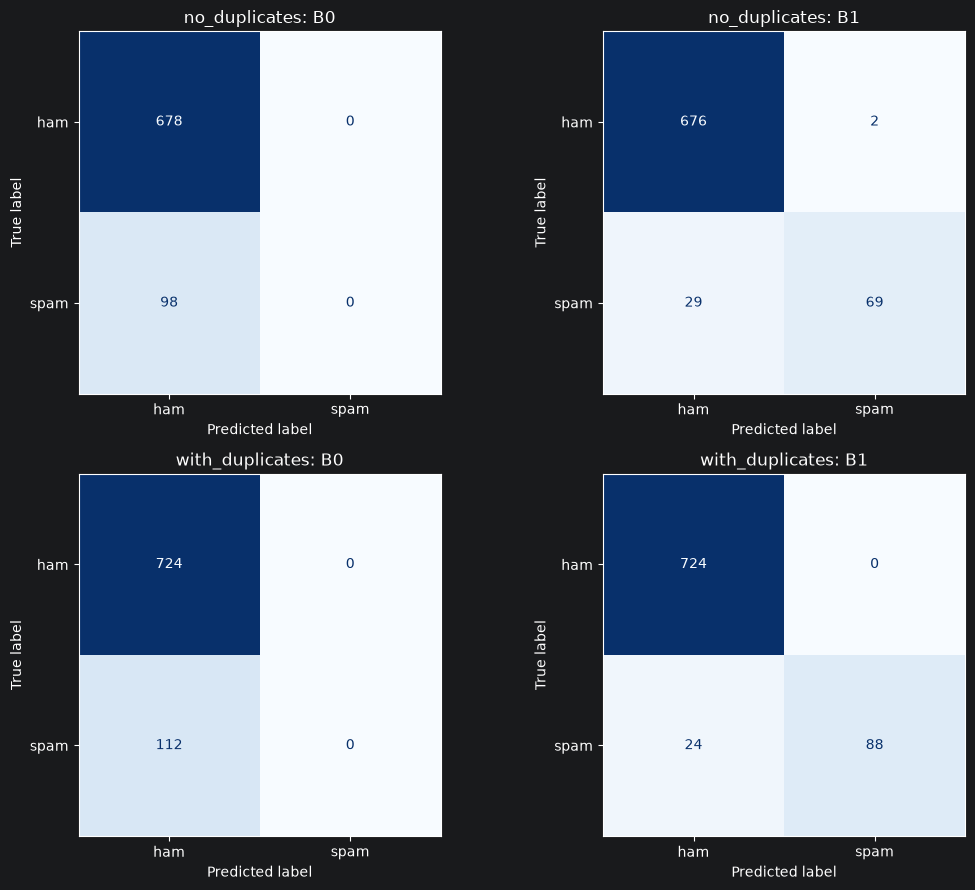

In [10]:
fig, axes = plt.subplots(2, 2, figsize=(11, 9))

for result, ax in zip(baseline_results, axes.flat):
    ConfusionMatrixDisplay(
        confusion_matrix=np.array(result.metrics["confusion_matrix"]),
        display_labels=result.metrics["class_labels"],
    ).plot(ax=ax, colorbar=False, cmap="Blues")
    ax.set_title(f"{result.dataset_variant}: {result.model_name}")

fig.tight_layout()
display(fig)
plt.close(fig)


## Preprocessing Experiments: P1-P3

Each variant adds one deterministic operation before the same TF-IDF and logistic regression used by B1. The shared hyperparameters and decision threshold remain unchanged. Each pipeline learns its own vocabulary and IDF on training data only.

| Variant | Operation | Hypothesis |
|---|---|---|
| P1 | Replace supported URLs with `zzurltokenzz` | Reduce URL vocabulary fragmentation while retaining the presence of a link. |
| P2 | Replace phone numbers and SMS shortcodes with `zzphonetokenzz` | Share evidence across variable contact numbers. |
| P3 | Shorten runs of three or more identical letters to two | Reduce variation in informal spelling while keeping case, numbers and punctuation. |

P1 and P2 separate the URL and phone parts of H1; money masking remains a later, independent experiment. P3 implements the letter-repetition part of H2. Repeated punctuation and the H3 typo robustness experiment remain separate.

P2 recognizes 9-15 digit phone candidates and contiguous 5-6 digit shortcodes. Recognizable URLs, emails, amounts, dates, times and decimal numbers are protected. These are fixed heuristics: a numeric identifier can resemble a shortcode, and some phone formats can be missed. The exact rules are saved with each run.

All four variants below use the same `no_duplicates` training and validation records. B1 is rerun with the same shared configuration as P1-P3. Test files are not loaded. The F1 difference is `F1(variant) - F1(B1)`; these first validation results do not establish statistical significance.


In [11]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay

from sms_spam.config import load_config
from sms_spam.experiments import PREPROCESSING_RESULTS_DIR, run_experiment
from sms_spam.preprocessing import transform_texts

preprocessing_examples = {
    "P1": "Visit https://example.com/prize now!",
    "P2": "Call +44 7700 900123 or text 82277.",
    "P3": "Soooo happy!!! Code: 11111.",
}

display(pd.DataFrame([
    {
        "variant": variant,
        "original": text,
        "transformed": transform_texts([text], variant=variant)[0],
    }
    for variant, text in preprocessing_examples.items()
]))


,variant,original,transformed
0,P1,Visit https://example.com/prize now!,Visit zzurltokenzz now!
1,P2,Call +44 7700 900123 or text 82277.,Call zzphonetokenzz or text zzphonetokenzz .
2,P3,Soooo happy!!! Code: 11111.,Soo happy!!! Code: 11111.


In [12]:
preprocessing_config = load_config()
preprocessing_results = [
    run_experiment(
        model_name,
        dataset_variant="no_duplicates",
        config=preprocessing_config,
        output_dir=PREPROCESSING_RESULTS_DIR,
    )
    for model_name in ("B1", "P1", "P2", "P3")
]

reference_predictions = preprocessing_results[0].predictions[["record_id", "y_true"]]
for result in preprocessing_results[1:]:
    if not result.predictions[["record_id", "y_true"]].equals(reference_predictions):
        raise ValueError("Preprocessing variants must use identical validation records and labels.")

preprocessing_comparison = pd.DataFrame([result.summary() for result in preprocessing_results])
reference_f1 = preprocessing_results[0].metrics["f1_spam"]
preprocessing_comparison["delta_f1"] = preprocessing_comparison["f1_spam"] - reference_f1
preprocessing_comparison.to_csv(PREPROCESSING_RESULTS_DIR / "summary.csv", index=False)

display(preprocessing_comparison[[
    "model", "f1_spam", "delta_f1", "precision_spam", "recall_spam",
    "macro_f1", "accuracy", "pr_auc", "average_precision", "fp", "fn",
]].round(4))


,model,f1_spam,delta_f1,precision_spam,recall_spam,macro_f1,accuracy,pr_auc,average_precision,fp,fn
0,B1,0.8166,0.0000,0.9718,0.7041,0.8971,0.9601,0.9555,0.9556,2,29
1,P1,0.8166,0.0000,0.9718,0.7041,0.8971,0.9601,0.9535,0.9537,2,29
2,P2,0.8864,0.0698,1.0000,0.7959,0.9359,0.9742,0.9726,0.9726,0,20
3,P3,0.8166,0.0000,0.9718,0.7041,0.8971,0.9601,0.9555,0.9557,2,29


In [13]:
preprocessing_changes = pd.DataFrame([
    {
        "model": result.model_name,
        "features": result.metadata["feature_count"],
        "train_changed": result.metadata["preprocessing_summary"]["train"]["changed_records"],
        "validation_changed": result.metadata["preprocessing_summary"]["val"]["changed_records"],
    }
    for result in preprocessing_results
])
display(preprocessing_changes)
display(preprocessing_comparison[[
    "model", "train_seconds", "inference_seconds", "inference_ms_per_message",
]].round(6))


,model,features,train_changed,validation_changed
0,B1,7065,0,0
1,P1,6998,96,15
2,P2,6763,337,73
3,P3,7041,151,26


,model,train_seconds,inference_seconds,inference_ms_per_message
0,B1,0.119311,0.016281,0.020980
1,P1,0.127358,0.025721,0.033146
2,P2,0.239347,0.051597,0.066491
3,P3,0.116087,0.022956,0.029583


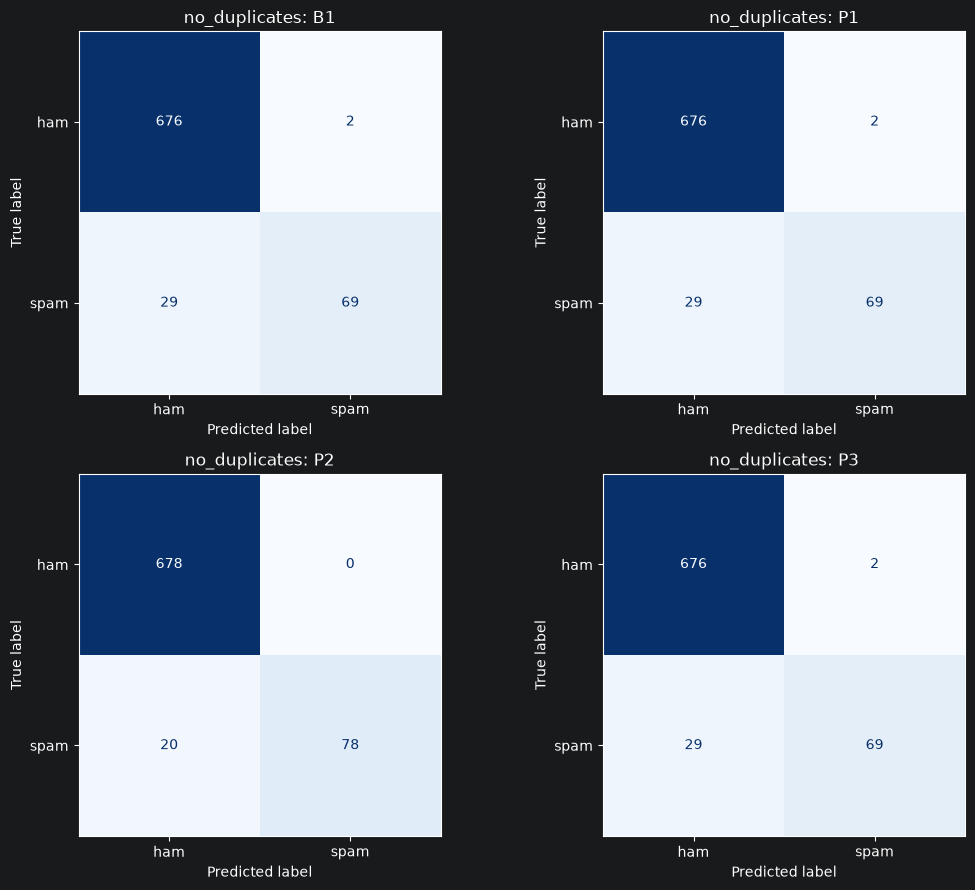

In [14]:
fig, axes = plt.subplots(2, 2, figsize=(11, 9))

for result, ax in zip(preprocessing_results, axes.flat):
    ConfusionMatrixDisplay(
        confusion_matrix=np.array(result.metrics["confusion_matrix"]),
        display_labels=result.metrics["class_labels"],
    ).plot(ax=ax, colorbar=False, cmap="Blues")
    ax.set_title(f"no_duplicates: {result.model_name}")

fig.tight_layout()
display(fig)
plt.close(fig)


Preprocessing comparison: with_duplicates (validation)


,model,f1_spam,delta_f1,precision_spam,recall_spam,macro_f1,accuracy,pr_auc,average_precision,fp,fn
0,B1,0.8800,0.0000,1.0000,0.7857,0.9318,0.9713,0.9679,0.9680,0,24
1,P1,0.8812,0.0012,0.9889,0.7946,0.9324,0.9713,0.9675,0.9676,1,23
2,P2,0.8911,0.0111,1.0000,0.8036,0.9381,0.9737,0.9773,0.9774,0,22
3,P3,0.8800,0.0000,1.0000,0.7857,0.9318,0.9713,0.9675,0.9676,0,24


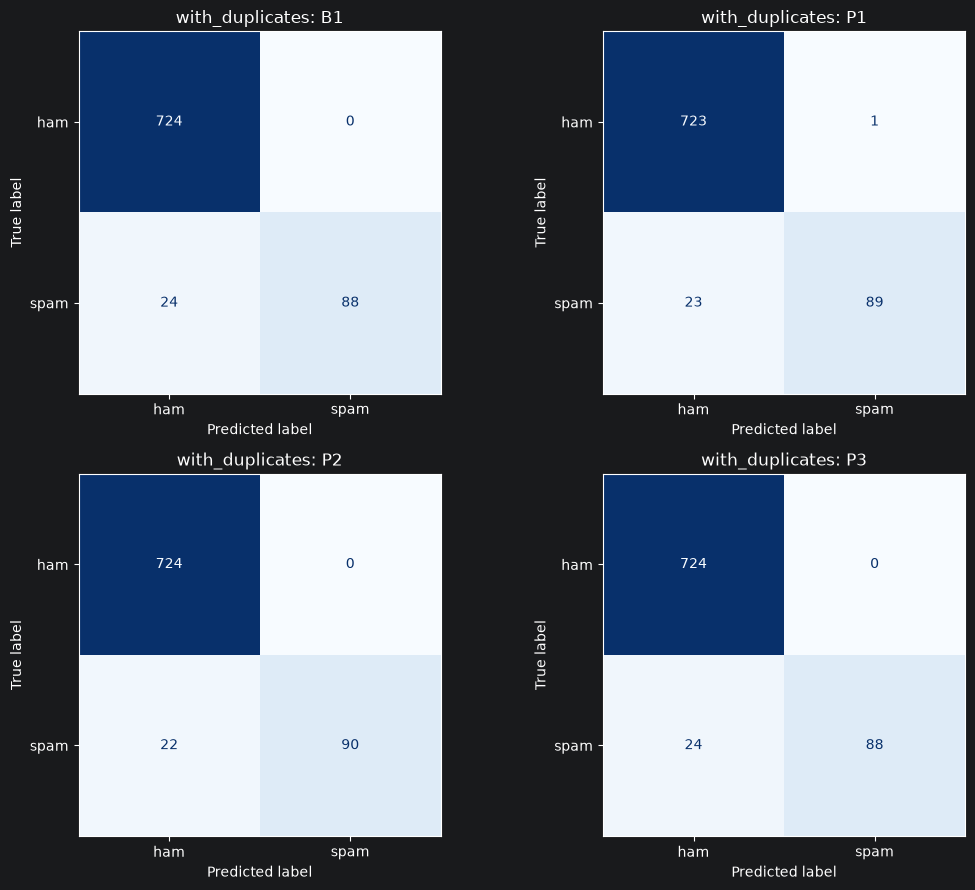

In [15]:
duplicate_preprocessing_config = load_config()
duplicate_preprocessing_results = [
    run_experiment(
        model_name,
        dataset_variant="with_duplicates",
        config=duplicate_preprocessing_config,
        output_dir=PREPROCESSING_RESULTS_DIR,
    )
    for model_name in ("B1", "P1", "P2", "P3")
]

duplicate_reference = duplicate_preprocessing_results[0].predictions[["record_id", "y_true"]]
for result in duplicate_preprocessing_results[1:]:
    if not result.predictions[["record_id", "y_true"]].equals(duplicate_reference):
        raise ValueError("Preprocessing variants must use identical validation records and labels.")

duplicate_preprocessing_comparison = pd.DataFrame([
    result.summary() for result in duplicate_preprocessing_results
])
duplicate_reference_f1 = duplicate_preprocessing_results[0].metrics["f1_spam"]
duplicate_preprocessing_comparison["delta_f1"] = (
    duplicate_preprocessing_comparison["f1_spam"] - duplicate_reference_f1
)
duplicate_preprocessing_comparison.to_csv(
    PREPROCESSING_RESULTS_DIR / "summary_with_duplicates.csv", index=False
)

print("Preprocessing comparison: with_duplicates (validation)")
display(duplicate_preprocessing_comparison[[
    "model", "f1_spam", "delta_f1", "precision_spam", "recall_spam",
    "macro_f1", "accuracy", "pr_auc", "average_precision", "fp", "fn",
]].round(4))

fig, axes = plt.subplots(2, 2, figsize=(11, 9))
for result, ax in zip(duplicate_preprocessing_results, axes.flat):
    ConfusionMatrixDisplay(
        confusion_matrix=np.array(result.metrics["confusion_matrix"]),
        display_labels=result.metrics["class_labels"],
    ).plot(ax=ax, colorbar=False, cmap="Blues")
    ax.set_title(f"with_duplicates: {result.model_name}")

fig.tight_layout()
display(fig)
plt.close(fig)


## Milestone 2 Summary

### Completed work

- Implemented B0 (training-majority class) and B1 (original text, word TF-IDF and logistic regression), with explicit configuration and a fixed decision threshold of 0.5.
- Implemented three independent preprocessing variants: URL masking (P1), phone/shortcode masking (P2), and repeated-letter normalization (P3). All use the same vectorizer settings and classifier as B1; learned components are fitted only on training data.
- Evaluated all preprocessing variants on the same 776 `no_duplicates` validation records. Saved configurations, record-level predictions, metrics, times and environment metadata in `reports/`.
- Ran the separate H4 diagnostic for B0/B1 on both dataset variants. Existing split-integrity and duplicate audits remain available in `eda.ipynb` and `reports/data_audit/`.

- Extended the preprocessing comparison to the same 836 `with_duplicates` validation records as an additional H4 diagnostic.

### Recorded validation results

| Variant | Spam F1 | Spam precision | Spam recall |
|---|---:|---:|---:|
| B1 | 0.8166 | 0.9718 | 0.7041 |
| P1 | 0.8166 | 0.9718 | 0.7041 |
| P2 | 0.8864 | 1.0000 | 0.7959 |
| P3 | 0.8166 | 0.9718 | 0.7041 |

B0 achieved spam F1 of 0 on both dataset variants. On `no_duplicates`, P2 increased F1 by 0.0698: false alarms decreased from 2 to 0, and missed spam decreased from 29 to 20. P1 and P3 did not change F1. P1 changed two predicted labels, correcting one error and introducing another; P3 kept all predicted labels but changed their probabilities.

The transformations affected 15 validation texts for P1, 73 for P2, and 26 for P3. Equal F1 therefore does not imply an inactive transformation.

For H4, B1 achieved 0.8166 F1 on `no_duplicates` and 0.8800 on `with_duplicates`. These validation sets contain different records, and the latter has known duplicate leakage; this difference alone cannot quantify the causal effect of duplication.

Additional validation results on `with_duplicates`:

| Variant | Spam F1 | Difference from B1 | Spam precision | Spam recall |
|---|---:|---:|---:|---:|
| B1 | 0.8800 | +0.0000 | 1.0000 | 0.7857 |
| P1 | 0.8812 | +0.0012 | 0.9889 | 0.7946 |
| P2 | 0.8911 | +0.0111 | 1.0000 | 0.8036 |
| P3 | 0.8800 | +0.0000 | 1.0000 | 0.7857 |

These additional results use the leaking split for the H4 diagnostic. Compare P1-P3 with B1 within this split; differences across dataset variants also involve different validation records.

These numbers describe the saved milestone 2 runs in `reports/baselines/summary.csv`, `reports/preprocessing/summary.csv`, and `reports/preprocessing/summary_with_duplicates.csv`. Review this snapshot when updating the experiments.

### Problems and limitations

- P2 uses fixed heuristics: numeric identifiers can resemble shortcodes, and some phone formats can be missed. P1 also supports a defined set of URL forms rather than every possible URL.
- Exact deduplication leaves normalized and near-duplicate candidates documented by the audit. This remains a limitation of the frozen split.
- Results use one fixed split per dataset variant. P2's improvement is preliminary; its stability and uncertainty have not yet been established. The configured classifiers use a deterministic solver.
- Test data has not been used for model selection or milestone 2 model evaluation. No test-set performance is claimed here.

### Next stage

- Extend the controlled preprocessing comparison with independent money masking and justified combinations; run the separate H3 robustness experiment with controlled typos.
- Evaluate a stronger representation/model M, such as frozen embeddings with a linear classifier, choosing settings only on validation data.
- In later milestones, compare with the agreed LLM, analyze at least 10 errors or disagreements, and report costs and uncertainty. Freeze the final choices before test evaluation, including a paired confidence interval for the B1 versus selected P difference.
